In [152]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import classification_report,accuracy_score
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

In [153]:
df = pd.read_csv('diabetes_risk_prediction_dataset.csv')

df.head(10)

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,...,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk
0,1,32.0,Male,Mexico,182.1,65.8,19.8,71.2,88.4,10.4,...,Yes,No,Good,Retired,Rural,4.4,60,Healthy Diet Plan,Yes,Moderate
1,2,42.0,Other,Saudi Arabia,148.5,101.2,45.9,121.8,247.3,11.3,...,Yes,Yes,Average,Government,Rural,2.1,99,Begin Diabetes Management Plan,Yes,High
2,3,89.0,Other,Argentina,158.1,NaN,37.9,131.8,141.9,6.3,...,Yes,No,Average,Government,Urban,2.8,80,Strict Blood Sugar Monitoring,Yes,High
3,4,87.0,Other,United States,190.9,95.9,26.3,99.1,90.1,7.4,...,No,No,Average,Business,Rural,1.5,82,Begin Diabetes Management Plan,Yes,High
4,5,27.0,Other,Australia,156.9,101.9,41.4,77.1,93.8,12.0,...,Yes,Yes,Poor,Private,Rural,1.6,93,Begin Diabetes Management Plan,Yes,High
5,6,29.0,Male,Bangladesh,153.3,86.3,36.7,77.1,142.2,5.0,...,Yes,Yes,Poor,Retired,Urban,4.4,69,Consult Endocrinologist Immediately,Yes,High
6,7,90.0,Other,Germany,160.8,67.2,26.0,113.6,126.6,6.6,...,Yes,No,Poor,Retired,Urban,4.8,68,Begin Diabetes Management Plan,Yes,High
7,8,80.0,Female,Bangladesh,190.3,116.9,32.3,67.4,146.2,6.7,...,Yes,No,Average,Government,Urban,4.6,80,Begin Diabetes Management Plan,Yes,High
8,9,40.0,Female,United States,146.2,107.6,50.3,86.6,237.5,10.9,...,No,No,Poor,Business,Rural,3.7,79,Medical Evaluation Required,Yes,High
9,10,73.0,Other,Malaysia,194.2,54.8,14.5,132.0,104.2,4.9,...,No,Yes,Good,Business,Rural,3.7,63,Weight Management Program,Yes,Moderate


In [154]:
df['Doctor_Consultation_Needed'].value_counts()

Doctor_Consultation_Needed
Yes    46426
No      3574
Name: count, dtype: int64

In [155]:
df.describe()

,Patient_ID,Age,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,...,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Sleep_Hours,Daily_Water_Intake_L,Diabetes_Risk_Score
count,50000.000000,49503.000000,47055.000000,47038.000000,50000.000000,50000.000000,49041.000000,48026.000000,50000.000000,50000.000000,...,49000.000000,49000.000000,49000.000000,49000.000000,50000.000000,48008.000000,48036.000000,47983.000000,50000.000000,50000.000000
mean,25000.500000,53.871099,170.018814,87.457003,30.924056,99.960790,159.905245,8.488061,142.607294,23.476724,...,220.168635,57.371731,135.014524,229.543259,85.124260,5.017460,89.933442,6.500917,2.998842,74.043920
std,14433.901067,21.130148,14.457787,24.500358,10.290091,23.086579,52.040575,2.313758,44.681799,12.403841,...,57.793626,18.720696,49.135613,98.234911,20.390334,2.875922,52.034642,2.027793,1.152273,15.598327
min,1.000000,18.000000,145.000000,45.000000,11.900000,60.000000,70.000000,4.500000,65.000000,2.000000,...,120.000000,25.000000,50.000000,60.000000,50.000000,0.000000,0.000000,3.000000,1.000000,13.000000
25%,12500.750000,35.000000,157.600000,66.300000,22.700000,80.000000,114.700000,6.500000,103.900000,12.800000,...,169.800000,41.300000,92.500000,144.700000,68.000000,2.500000,44.900000,4.700000,2.000000,64.000000
50%,25000.500000,54.000000,170.000000,87.300000,30.000000,99.800000,159.900000,8.500000,142.600000,23.400000,...,220.400000,57.300000,135.100000,229.500000,85.000000,5.000000,89.800000,6.500000,3.000000,75.000000
75%,37500.250000,72.000000,182.600000,108.600000,37.800000,119.900000,205.100000,10.500000,181.500000,34.300000,...,270.500000,73.600000,177.700000,314.600000,103.000000,7.500000,135.200000,8.300000,4.000000,86.000000
max,50000.000000,90.000000,195.000000,130.000000,61.700000,140.000000,250.000000,12.500000,220.000000,45.000000,...,320.000000,90.000000,220.000000,400.000000,120.000000,10.000000,180.000000,10.000000,5.000000,100.000000


In [156]:
df.nunique()

Patient_ID                    50000
Age                              73
Gender                            3
Country                          25
Height_cm                       501
Weight_kg                       851
BMI                             497
Waist_Circumference_cm          801
Blood_Glucose                  1801
HbA1c                            81
Fasting_Blood_Sugar            1551
Insulin_Level                   431
Blood_Pressure_Systolic         101
Blood_Pressure_Diastolic         61
Total_Cholesterol              2001
HDL                             651
LDL                            1701
Triglycerides                  3401
Heart_Rate                       71
Physical_Activity_Level           3
Exercise_Hours_Per_Week         101
Daily_Walking_Minutes          1801
Diet_Quality                      3
Sugar_Intake_Level                3
Sleep_Hours                      71
Stress_Level                      3
Smoking_Status                    3
Alcohol_Consumption         

In [157]:
df = df.drop(columns = ['Patient_ID','Country','Work_Type','Residence_Type','AI_Health_Recommendation','Diabetes_Risk_Score'])

df.head()

,Age,Gender,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,...,Alcohol_Consumption,Family_History_Diabetes,Hypertension,Heart_Disease,Fatty_Liver,PCOS,Medication_Adherence,Daily_Water_Intake_L,Doctor_Consultation_Needed,Diabetes_Risk
0,32.0,Male,182.1,65.8,19.8,71.2,88.4,10.4,149.5,27.4,...,Never,Yes,No,Yes,Yes,No,Good,4.4,Yes,Moderate
1,42.0,Other,148.5,101.2,45.9,121.8,247.3,11.3,199.3,18.3,...,Frequently,Yes,No,Yes,Yes,Yes,Average,2.1,Yes,High
2,89.0,Other,158.1,NaN,37.9,131.8,141.9,6.3,219.6,23.9,...,Frequently,Yes,No,No,Yes,No,Average,2.8,Yes,High
3,87.0,Other,190.9,95.9,26.3,99.1,90.1,7.4,217.7,36.7,...,Occasionally,Yes,Yes,No,No,No,Average,1.5,Yes,High
4,27.0,Other,156.9,101.9,41.4,77.1,93.8,12.0,153.5,22.3,...,Occasionally,No,Yes,Yes,Yes,Yes,Poor,1.6,Yes,High


In [158]:
print(f"Duplicated Rows: {df.duplicated().sum()}")
missing = df.isnull().sum().sort_values(ascending = False)

pd.DataFrame({"Missing":missing})[missing>0]


Duplicated Rows: 0


,Missing
Weight_kg,2962
Height_cm,2945
Sleep_Hours,2017
Exercise_Hours_Per_Week,1992
HbA1c,1974
Daily_Walking_Minutes,1964
HDL,1000
Medication_Adherence,1000
Triglycerides,1000
LDL,1000


In [159]:
numeric_cols = df.select_dtypes(include='number').columns
categorial_cols = df.select_dtypes(include='object').columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

for cat_col in categorial_cols:
    df[cat_col] = df[cat_col].fillna(df[cat_col].mode()[0])

print(f"Number of null values: {df.isnull().sum().sum()}")

Number of null values: 0


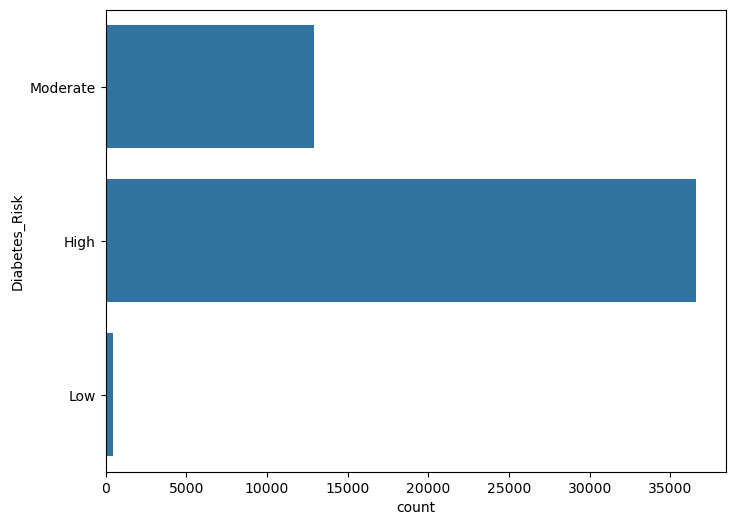

Diabetes_Risk
High        36593
Moderate    12937
Low           470
Name: count, dtype: int64

In [160]:
plt.figure(figsize = (8,6))
sns.countplot(df['Diabetes_Risk'])
plt.show()
df['Diabetes_Risk'].value_counts()

In [161]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].unique())


Gender:
['Male' 'Other' 'Female']

Physical_Activity_Level:
['Moderate' 'High' 'Low']

Diet_Quality:
['Healthy' 'Average' 'Poor']

Sugar_Intake_Level:
['Low' 'High' 'Moderate']

Stress_Level:
['Moderate' 'High' 'Low']

Smoking_Status:
['Former' 'Current' 'Never']

Alcohol_Consumption:
['Never' 'Frequently' 'Occasionally']

Family_History_Diabetes:
['Yes' 'No']

Hypertension:
['No' 'Yes']

Heart_Disease:
['Yes' 'No']

Fatty_Liver:
['Yes' 'No']

PCOS:
['No' 'Yes']

Medication_Adherence:
['Good' 'Average' 'Poor']

Doctor_Consultation_Needed:
['Yes' 'No']

Diabetes_Risk:
['Moderate' 'High' 'Low']


In [162]:
diabetes_risk = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}
df['Diabetes_Risk'] = df['Diabetes_Risk'].map(diabetes_risk)

medication_adherence ={
    'Poor': 0,
    'Average': 1,
    'Good': 2
}
df['Medication_Adherence'] = df['Medication_Adherence'].map(medication_adherence)

physical_activity ={
    'Low': 0,
    'Moderate': 1,
    'High': 2
}
df['Physical_Activity_Level'] = df['Physical_Activity_Level'].map(physical_activity)

diet_quality ={
    'Poor': 0,
    'Average': 1,
    'Healthy': 2
}
df['Diet_Quality'] = df['Diet_Quality'].map(diet_quality)

sugar_intake ={
    'Low': 0,
    'Moderate': 1,
    'High': 2
}
df['Sugar_Intake_Level'] = df['Sugar_Intake_Level'].map(sugar_intake)

stress_level ={
    'Low': 0,
    'Moderate': 1,
    'High': 2
}
df['Stress_Level'] = df['Stress_Level'].map(stress_level)

smoking_status ={
    'Never': 0,
    'Former': 1,
    'Current': 2
}
df['Smoking_Status'] = df['Smoking_Status'].map(smoking_status)

alcohol_consumption ={
    'Never': 0,
    'Occasionally': 1,
    'Frequently': 2
}
df['Alcohol_Consumption'] = df['Alcohol_Consumption'].map(alcohol_consumption)

cat_cols = df.select_dtypes(include='object').columns

df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

df.head()


,Age,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,...,Daily_Water_Intake_L,Diabetes_Risk,Gender_Male,Gender_Other,Family_History_Diabetes_Yes,Hypertension_Yes,Heart_Disease_Yes,Fatty_Liver_Yes,PCOS_Yes,Doctor_Consultation_Needed_Yes
0,32.0,182.1,65.800000,19.8,71.2,88.4,10.4,149.5,27.4,94,...,4.4,1,1,0,1,0,1,1,0,1
1,42.0,148.5,101.200000,45.9,121.8,247.3,11.3,199.3,18.3,148,...,2.1,2,0,1,1,0,1,1,1,1
2,89.0,158.1,87.457003,37.9,131.8,141.9,6.3,219.6,23.9,101,...,2.8,2,0,1,1,0,0,1,0,1
3,87.0,190.9,95.900000,26.3,99.1,90.1,7.4,217.7,36.7,120,...,1.5,2,0,1,1,1,0,0,0,1
4,27.0,156.9,101.900000,41.4,77.1,93.8,12.0,153.5,22.3,190,...,1.6,2,0,1,0,1,1,1,1,1


In [163]:
correlation = df.corr(numeric_only=True)['Diabetes_Risk'].sort_values(ascending=False)

pd.DataFrame({"Correlation":correlation})

,Correlation
Diabetes_Risk,1.000000
Doctor_Consultation_Needed_Yes,0.497162
Fasting_Blood_Sugar,0.379986
HbA1c,0.269205
Family_History_Diabetes_Yes,0.220404
Age,0.209812
BMI,0.161372
Weight_kg,0.142841
Hypertension_Yes,0.137778
Blood_Pressure_Systolic,0.119854


In [164]:
df = df.drop(columns=['Gender_Other','Gender_Male'])

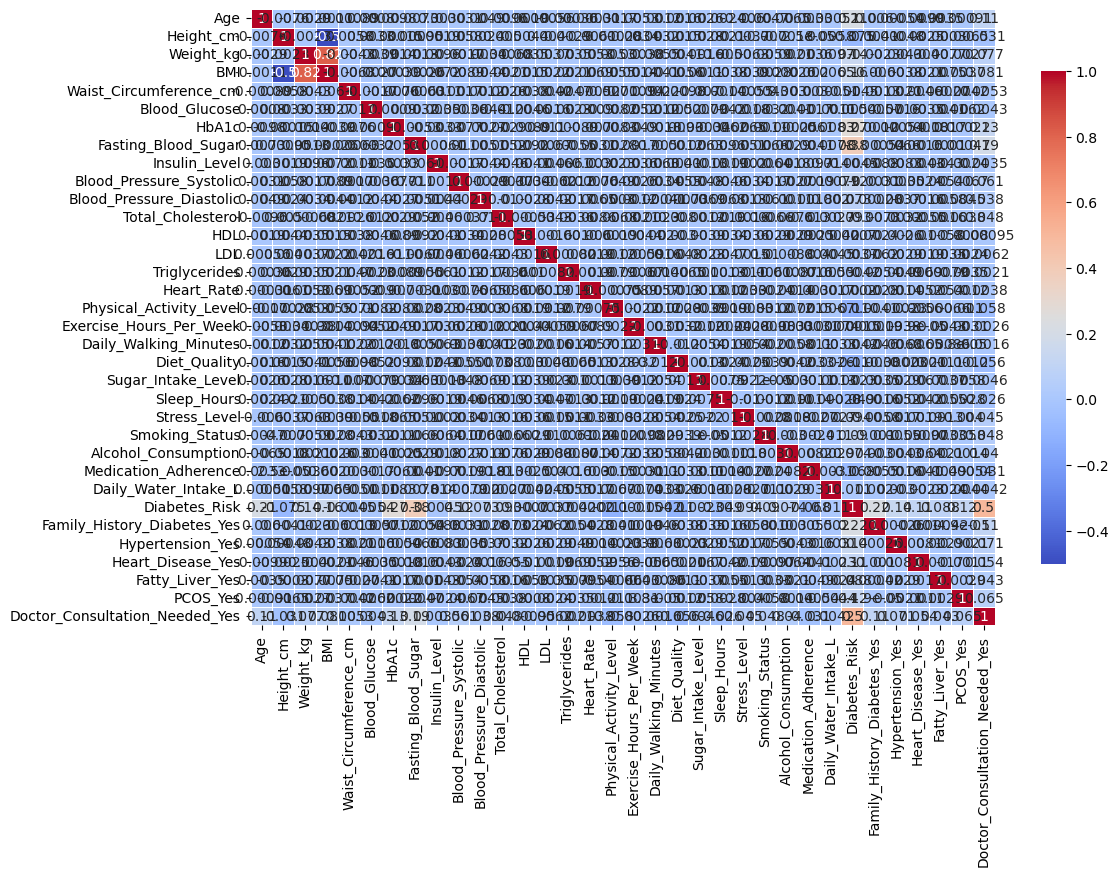

In [165]:
cm = df.corr()

plt.figure(figsize=(12,8))
sns.heatmap(cm,
            cmap="coolwarm",
            fmt = '.2g',
            annot = True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8})
plt.show()

In [166]:
x = df.drop(columns = ['Diabetes_Risk'])
y = df['Diabetes_Risk']

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42, stratify = y)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [167]:
knn = KNeighborsClassifier()

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    'metric': ['euclidean', 'manhattan']
}

In [168]:
grid_search = GridSearchCV(
    knn,
    param_grid_knn,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(x_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 9}
Best CV Accuracy: 0.840425


In [ ]:
best_knn = grid_search.best_estimator_

yknn_pred = best_knn.predict(x_test_scaled)

cr_knn = classification_report(y_test,yknn_pred)
acc_knn = accuracy_score(y_test,yknn_pred)

print(cr_knn)
print(acc_knn)

              precision    recall  f1-score   support

           0       0.69      0.12      0.20        94
           1       0.86      0.48      0.62      2587
           2       0.84      0.98      0.91      7319

    accuracy                           0.85     10000
   macro avg       0.80      0.53      0.58     10000
weighted avg       0.85      0.85      0.83     10000

0.8456


In [170]:
# trainknn_pred = knn.predict(x_train_scaled)
# testknn_pred = knn.predict(x_test_scaled)

# trainknn_accuracy = accuracy_score(y_train, trainknn_pred)
# testknn_accuracy = accuracy_score(y_test, testknn_pred)

# print("Training Accuracy KNN:", trainknn_accuracy)
# print("Testing Accuracy KNN:", testknn_accuracy)

In [188]:
dt = DecisionTreeClassifier(random_state = 42)

param_grid_dt = {
    'criterion': ['gini','entropy','log_loss'],
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
}
grid_search = GridSearchCV(
    dt,
    param_grid_dt,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(x_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'criterion': 'entropy', 'max_depth': 10}
Best CV Accuracy: 0.8727749999999999


In [189]:
best_dt = grid_search.best_estimator_

ydt_pred = best_dt.predict(x_test)

cr_dt = classification_report(y_test,ydt_pred)
acc_dt = accuracy_score(y_test,ydt_pred)

print(cr_dt)
print(acc_dt)

              precision    recall  f1-score   support

           0       0.47      0.48      0.48        94
           1       0.80      0.72      0.76      2587
           2       0.91      0.94      0.93      7319

    accuracy                           0.88     10000
   macro avg       0.73      0.71      0.72     10000
weighted avg       0.88      0.88      0.88     10000

0.8799


In [173]:
# traindt_pred = model.predict(x_train)
# testdt_pred = model.predict(x_test)

# traindt_accuracy = accuracy_score(y_train, traindt_pred)
# testdt_accuracy = accuracy_score(y_test, testdt_pred)

# print("Training Accuracy Decision Tree:", traindt_accuracy)
# print("Testing Accuracy Decision Tree:", testdt_accuracy)

In [179]:
svm = SVC(random_state = 42)

param_grid_svm = [
        {
        'kernel': ['linear'],
        'C': [0.1, 1, 10]
    },
    {
        'kernel': ['rbf'],
        'C': [0.1, 1, 10],
        'gamma': [0.01, 0.1]
    }
]
grid_search = GridSearchCV(
    svm,
    param_grid_svm,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(x_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV Accuracy: 0.9226999724040649


In [187]:
best_svm = grid_search.best_estimator_

ysvm_pred = best_dt.predict(x_test_scaled)

cr_svm = classification_report(y_test,ysvm_pred)
acc_svm = accuracy_score(y_test,ysvm_pred)

print(cr_svm)
print(acc_svm)

              precision    recall  f1-score   support

           0       0.74      0.57      0.65        94
           1       0.87      0.84      0.85      2587
           2       0.95      0.96      0.95      7319

    accuracy                           0.92     10000
   macro avg       0.85      0.79      0.82     10000
weighted avg       0.92      0.92      0.92     10000

0.9248


In [ ]:
# trainsvm_pred = svm.predict(x_train_scaled)
# testsvm_pred = svm.predict(x_test_scaled)

# trainsvm_accuracy = accuracy_score(y_train, trainsvm_pred)
# testsvm_accuracy = accuracy_score(y_test, testsvm_pred)

# print("Training Accuracy SVM:", trainsvm_accuracy)
# print("Testing Accuracy SVM:", testsvm_accuracy)

Training Accuracy SVM: 0.952475
Testing Accuracy SVM: 0.9201


In [ ]:
final_svm = SVC(
    best_svm,
    probability=True,
    random_state=42
)

final_svm.fit(x_train_scaled, y_train)